# Example - Selecting FRET populations

This notebook replicates the selecting FRET populations notebooks of FRETBursts in smfBursts.

> Old text in insets

> `Old code in # comments`
>
> `With equivalent new code below`

> *This notebook is part of smFRET burst analysis software [FRETBursts](https://opensmfs.github.io/FRETBursts/).*
> 
> In this notebook shows two methods to select FRET populations: size filtering and DCBS.
> For a complete tutorial on burst analysis see 
> [FRETBursts - us-ALEX smFRET burst analysis](us-ALEX_translation.ipynb)

This notebook shows how to select and plot data.

**See also** [Gates](GatesTutorial.ipynb) for an indepth description of how to select data in smfBursts.

The first step is to import PhotonBursts, we will also import some common libraries.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# from fretbursts import * # prefer explicit import
import smfbursts as smf

## Get and process data

Enter the name of your file between the quotes after `full_fname = `

Then we will load the relevant data

In [2]:
full_fname = "data/HP3_TE300_SPC630.hdf5"

# d = loader.photon_hdf5(full_fname)
raw = smf.hdf5.load(full_fname)

# loader.alex_apply_period(d)
data = smf.hdf5.regularize_dets(raw)

And finally start to define analysis parameters

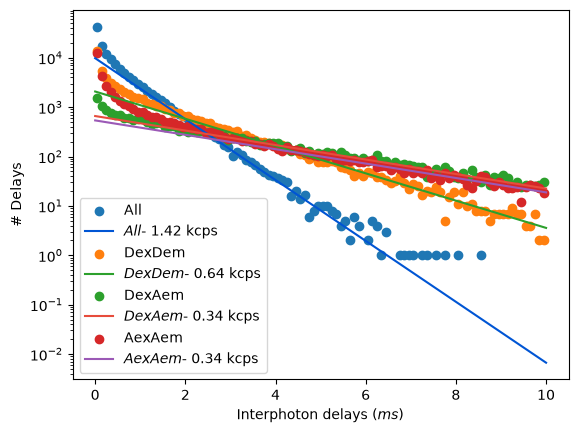

In [3]:
# d.calc_bg(bg.exp_fit, time_s=1000, tail_min_us=(800, 4000, 1500, 1000, 3000))
bg = smf.ff.make_bg(data, period=60.0, tail_min=500e-6, 
                    func=smf.bg.exp_mlefit, auto_threshold=True)

smf.plot.hist_interphoton(data, bg['bg'], 0, 
                          streams=smf.ff.ALEXdefaults.streams, 
                          labels=smf.ff.ALEXdefaults.stream_labels, 
                          fit_streams_kwargs=smf.ff.ALEXdefaults.stream_colors);

In [4]:
# d.burst_search(m=10, F=6.0)
acbs = smf.ff.make_burst_search(bg['bg'], m=10, F=6.0,
                                streams=smf.PhSel('0ex_1ex1em'))

# ds = d.select_bursts(select_bursts.size, add_naa=True, th1=40)
ac_gAll = smf.make_geq_gate(acbs['NphAll_bg'], 40.0)

## Filtering method

We can select the FRET population (S ~ 0.5) combining these two filters:

1. Filter out A-only: select bursts with counts during $D_{ex}$ > threshold
2. Filter out D-only: select bursts with counts in $A_{ex}A_{em}$ > threshold

In code, this becomes:

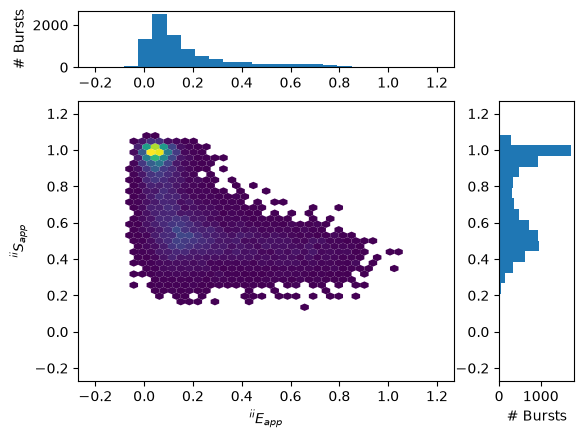

In [5]:
# ds_no_Aonly = ds.select_bursts(select_bursts.size, th1=30)
ac_gDactive = ac_gAll & smf.make_geq_gate(acbs['NphDex_bg'], 30.0)


# alex_jointplot(ds)
smf.plot.jointplot(data, acbs['E_bg'], acbs['S_bg'], gate=ac_gDactive,
                   cfunc=smf.plot.hexbin,
                   cplot_kwargs=smf.ff.ALEXdefaults.hexbin,
                   hplot_kwargs={'bins':np.linspace(-0.2,1.2, 25)});

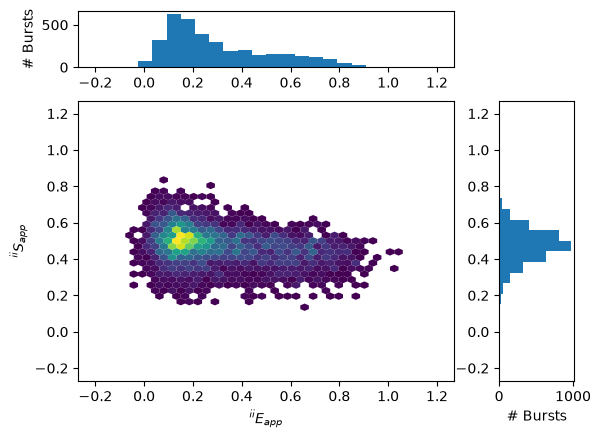

In [6]:
# ds_fret = ds_no_Aonly.select_bursts(select_bursts.naa, th1=30)
ac_gFRET = ac_gDactive & smf.make_geq_gate(acbs['NphAA_bg'], 30)

# alex_jointplot(ds_fret)
smf.plot.jointplot(data, acbs['E_bg'], acbs['S_bg'], gate=ac_gFRET,
                   cfunc=smf.plot.hexbin,
                   cplot_kwargs=smf.ff.ALEXdefaults.hexbin,
                   hplot_kwargs={'bins':np.linspace(-0.2,1.2, 25)});

### DCBS Method

With Dual-channel Burst Search (DCBS),
we define bursts as the intersection of a burst search performed on $D_{ex}$ stream and 
one performed on $A_{ex}A_{em}$ stream (see ([Nir et al. JPC 2006](https://doi.org/10.1021/jp063483n))).

In this way we filter D-only and A-only bursts,
but also we reduce the burst duration of FRET bursts to the portion where
$D_{ex}$ and $A_{ex}A_{em}$ both give signal. This property allows filtering 
acceptor photo-blinking, that causes part of a burst to appear as D-only.

To perform DCBS in FRETBursts we use:

In [7]:
# d_fret_2 = bext.burst_search_and_gate(d)
dcbs_streams = (smf.PhSel('0ex'), smf.PhSel('1ex1em'))
dcbs1 = smf.ff.make_burst_search(bg['bg'], m=10, F=6.0,
                                 streams=dcbs_streams)

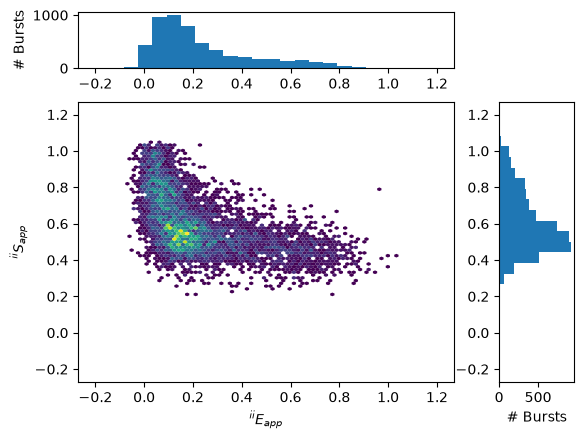

In [8]:
# ds_fret_2 = d_fret_2.select_bursts(select_bursts.size, th1=30)
d1_gFRET = smf.make_geq_gate(dcbs1['NphDex_bg'], 30)

# alex_jointplot(ds_fret_2);
smf.plot.jointplot(data, dcbs1['E_bg'], dcbs1['S_bg'], gate=d1_gFRET,
                   cfunc=smf.plot.hexbin, 
                   cplot_kwargs={'gridsize':80, 'extent':(-0.2,1.2,-0.2,1.2), 
                                 'mincnt':1, 'edgecolor':'none', 
                                 'linewidth':0.2},
                   hplot_kwargs={'bins':np.linspace(-0.2,1.2, 25)});

> The function [bext.burst_search_and_gate()](https://fretbursts.readthedocs.io/en/latest/plugins.html?highlight=burst_search_and#fretbursts.burstlib_ext.burst_search_and_gate)
> performs two burst searches on the photon streams defined by `ph_sel1` and `ph_sel2` arguments
> (by default `ph_sel1=Ph_sel(Dex='DAem')` and `ph_sel2=Ph_sel(Aex='Aem')`, i.e. $D_{ex}$ and $A_{ex}A_{em}$).
> Then, it takes the "intersection in time" (and-gate) for the two sets of bursts.

> `burst_search_and_gate` accepts the same 
> *m*, *F*, and *min_rate_cps* arguments as [Data.burst_search()](https://fretbursts.readthedocs.io/en/latest/data_class.html#fretbursts.burstlib.Data.burst_search).
> It is also possible to use different burst search parameters for the two
> burst searches:

In `smf.fretfactory.make_burst_search()` we can perform any number of burst searches and take their intersection.
This is done by specifying multiple photon streams in the ``streams`` keyword argument.
Other arguments can also be specified as sequences of values to adjust the value per burst search.
The function automatically converts all single value arguments into arrays of length in streams.

In [9]:
# d_fret_22 = bext.burst_search_and_gate(d, m=(8, 10), F=(5, 12))
dcbs_streams = (smf.PhSel('0ex'), smf.PhSel('1ex1em'))
dcbs2 = smf.fretfactory.make_burst_search(bg['bg'], m=(8, 10), F=(5.0, 12.0),
                                          streams=dcbs_streams)

Before plotting we still need to select bursts by size:

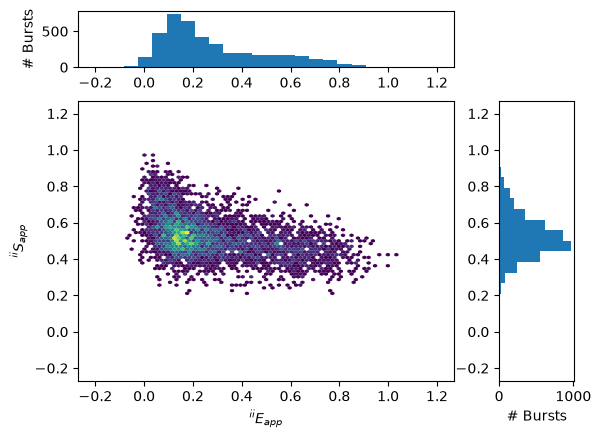

In [10]:
# ds_fret_22 = d_fret_22.select_bursts(select_bursts.size, th1=30)
d2_gFRET = smf.make_geq_gate(dcbs2['NphDex_bg'], 30)

# alex_jointplot(ds_fret_22);
smf.plot.jointplot(data, dcbs2['E_bg'], dcbs2['S_bg'], gate=d2_gFRET,
                   cfunc=smf.plot.hexbin,
                   cplot_kwargs={'gridsize':80, 'extent':(-0.2,1.2,-0.2,1.2),
                                 'mincnt':1, 'edgecolor':'none',
                                 'linewidth':0.2},
                   hplot_kwargs={'bins':np.linspace(-0.2,1.2, 25)});

**Reminder: print your citations (new to smfBursts)**

In [11]:
smf.print_citations()

1. Ingargiola, A., Lerner, E., Chung, S. Y., Weiss, S. & Michalet, X.
    FRETBursts: An open source toolkit for analysis of freely-diffusing Single-
    molecule FRET. PLoS ONE 11, 1–27 (2016).
2. Müller, B. K., Zaychikov, E., Bräuchle, C. & Lamb, D. C. Pulsed interleaved
    excitation. Biophysical Journal 89, 3508–3522 (2005).
3. Laurence, T. A., Kong, X., Jager, M. & Weiss, S. Probing structural
    heterogeneities and fluctuations of nucleic acids and denatured proteins.
    Proceedings of the National Academy of Sciences 102, 17348–17353 (2005).
4. Eggeling, C., Fries, J. R., Brand, L., Günther, R. & Seidel, C. A. M.
    Monitoring conformational dynamics of a single molecule by selective
    fluorescence spectroscopy. Proc. Natl. Acad. Sci. U.S.A. 95, 1556–1561
    (1998).
5. Fries, J. R., Brand, L., Eggeling, C., Köllner, M. & Seidel, C. A. M.
    Quantitative Identification of Different Single Molecules by Selective Time-
    Resolved Confocal Fluorescence Spectroscopy. J. Phy

**and to show the params used with the `.description` property**

In [12]:
print(dcbs2['nphbg'].description)

Table: NphBG
Params:
  single: True
Parents:
  base:  Table: BurstOvlp
    Params:
      fuse: 0.0
      truthtable: [[False False]
                   [False  True]]
    Parents:
      bases:  
        - Table: Bursts
          Params:
            func: smfbursts.bursttables.burstsearch_mwindowF_bg
            stream: 0ex
            m: 8
            F: 5.0
            c: -1.0
            fuse: 0.0
          Parents:
            bg:  Table: BG
              Params:
                compute_stream: single_all
                func: smfbursts.backgroundtables.exp_mlefit
                tail_min: [0.0005 0.0005 0.0005 0.0005 0.0005]
                auto_threshold: True
                F_bg: 2.0
              Parents:
                base:  Table: Periods
                  Params:
                    period: 60.0
                    start_at: time_min
                    stop_at: over
                    detdef: DetDef2ex2em  
        - Table: Bursts
          Params:
            func: smfbu

End of tutorial.